In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout, Input
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.datasets import reuters
import matplotlib.pyplot as plt
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [ ]:
num_words = 10000     # TODO (Q1a): 10000
maxlen    = 200     # TODO (Q1a): 200

(X_train, y_train), (X_test, y_test) = reuters.load_data(num_words=num_words, test_split=0.2)

# Q1b) pad both sets
X_train = pad_sequences(X_train, maxlen=maxlen)   # TODO (Q1b): maxlen
X_test  = pad_sequences(X_test,  maxlen=maxlen)   # TODO (Q1b): maxlen

# Q1c) how many topic classes? (labels are integers 0..45)
num_classes = int(max(y_train))+1   # TODO (Q1c): int(max(y_train)) + 1
print("X_train:", X_train.shape, " classes:", num_classes)

2110848/2110848 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
X_train: (8982, 200)  classes: 46


In [ ]:
assert X_train.shape[1] == 200, "pad reviews to length 200"
assert num_classes == 46, "Reuters has 46 topic classes"
print("Task 1 looks correct ✔")

Task 1 looks correct ✔


In [ ]:
model = Sequential()
model.add(Input(shape=(maxlen,)))

# Q2a) Embedding
model.add(Embedding(input_dim=num_words, output_dim=128))   # TODO (Q2a): num_words, 128

# Q2b) Bidirectional LSTM -> one summary vector
model.add(Bidirectional(LSTM(64, return_sequences=False)))   # TODO (Q2b): 64, False

model.add(Dropout(0.5))

# Q2c) Output: one neuron PER CLASS with softmax
model.add(Dense(num_classes, activation='softmax'))   # TODO (Q2c): num_classes, 'softmax'

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 46)             │         5,934 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,384,750 (5.28 MB)

 Trainable params: 1,384,750 (5.28 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Q3a) compile for integer multi-class labels
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',              # TODO (Q3a): 'sparse_categorical_crossentropy'
              metrics=['accuracy'])

# Q3b) train with a validation split
history = model.fit(X_train, y_train,
                    validation_split=0.2,   # TODO (Q3b): 0.2
                    epochs=10,             # TODO (Q3b): 10
                    batch_size=64)         # TODO (Q3b): 64

Epoch 1/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.4429 - loss: 2.3268 - val_accuracy: 0.5203 - val_loss: 1.8863
Epoch 2/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.5243 - loss: 1.8918 - val_accuracy: 0.5198 - val_loss: 1.9247
Epoch 3/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.5197 - loss: 1.8270 - val_accuracy: 0.5403 - val_loss: 1.7585
Epoch 4/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.5521 - loss: 1.7425 - val_accuracy: 0.5654 - val_loss: 1.6903
Epoch 5/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.6092 - loss: 1.6056 - val_accuracy: 0.6043 - val_loss: 1.5970
Epoch 6/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.6315 - loss: 1.4863 - val_accuracy: 0.6032 - val_loss: 1.5881
Epoch 7/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.6423 - loss: 1.4229 - val_accuracy: 0.6016 - val_loss: 1.6649
Epoch 8/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.6461 - loss: 1.3756 - val_acc

71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6282 - loss: 1.6007
Test accuracy: 62.82%


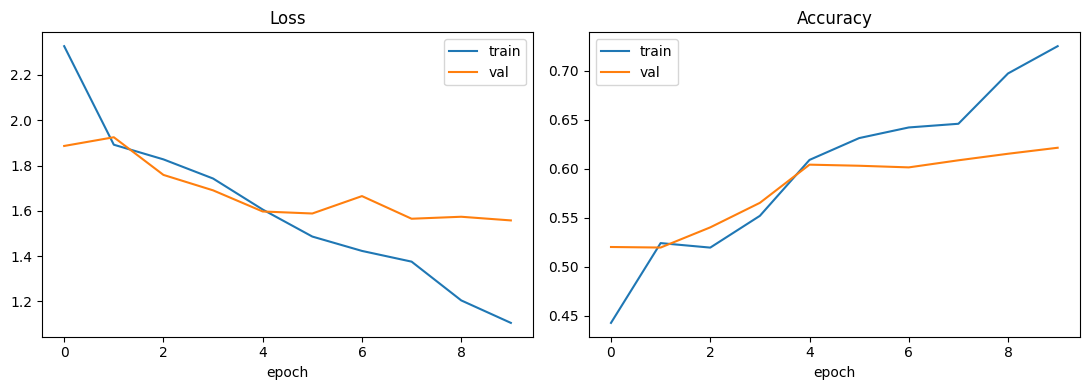

In [ ]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test accuracy: {accuracy*100:.2f}%")   # expect ~ 65-72%

plt.figure(figsize=(11,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')      # TODO (Q4a): 'val_loss'
plt.title('Loss'); plt.xlabel('epoch'); plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')      # TODO (Q4b): 'val_accuracy'
plt.title('Accuracy'); plt.xlabel('epoch'); plt.legend()
plt.tight_layout(); plt.show()

In [ ]:
probs = model.predict(X_test[:5], verbose=0)   # shape (5, 46)

# Q5) pick the most likely topic for each review
pred_classes = np.argmax(probs,axis=1)   # TODO (Q5): np.argmax(probs, axis=1)

for i in range(5):
    print(f"true topic: {y_test[i]:2d}   predicted: {pred_classes[i]:2d}")

true topic:  3   predicted:  3
true topic: 10   predicted: 16
true topic:  1   predicted: 20
true topic:  4   predicted:  3
true topic:  4   predicted: 13


## Task 6 — Short questions *(write answers here)*

1. What are the **three** differences between this model and Example A (output units, activation,
   loss)?
2. Why `sparse_categorical_crossentropy` here instead of `categorical_crossentropy`? (Hint: are
   the labels one-hot or integers?)
3. The Embedding and Bidirectional LSTM layers are **identical** to Example A. What does that tell
   you about reusing a sequence backbone across tasks?
4. Multi-class accuracy (~68%) is lower than IMDB (~87%). Give one reason why 46-way is harder than
   2-way.

> **Your answers:**
> 1. **Output Units**: This model has 46 output units (one for each class) instead of 1 unit. **Activation**: It uses `softmax` instead of `sigmoid`. **Loss**: It uses `sparse_categorical_crossentropy` instead of `binary_crossentropy`.
> 2. We use `sparse_categorical_crossentropy` because the targets/labels are integers (0 to 45) rather than one-hot encoded vectors.
> 3. It tells us that a sequence backbone (embedding + recurrent sequence encoder) is highly versatile and can extract general language features that are transferrable across different downstream tasks (e.g., binary sentiment analysis vs. multi-class topic classification).
> 4. A 46-way classification task is much more difficult than a 2-way classification task because the random-guess baseline is significantly lower (approx. 2.2% vs. 50%), there are finer, more subtle semantic boundaries between some of the 46 topic classes, and the distribution of samples per class can be highly imbalanced.